# 2. Análisis exploratorio de datos

Todo el EDA se hace **solo con el conjunto de entrenamiento**. Es la serie de la finca entre 1981 y 2020; el periodo 2021–2025 se reservó en el capítulo anterior y no se mira hasta la evaluación final.

El objetivo de pronóstico es la lluvia acumulada semanal. Por eso muchos análisis se hacen en escala semanal además de la diaria.

In [2]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as cfg
np.random.seed(cfg.SEED)
plt.rcParams["figure.dpi"] = 110
import seaborn as sns
from scipy import stats
from src import modelado as md

In [3]:
df = pd.read_csv(cfg.DATA_PROCESSED / cfg.ARCHIVO_DATOS, parse_dates=["fecha"])
OBJ = "PRECTOTCORR"
train_df = df[df["fecha"] < cfg.INICIO_TEST].copy()     # entrenamiento 1981-2020; 2021-2025 es prueba
REF = df["punto"].iloc[0]                                # un solo sitio: la celda de la finca
print(train_df.shape, train_df["fecha"].min().date(), "→", train_df["fecha"].max().date(), "| sitio:", REF)
VARS = [c for c in cfg.POWER_PARAMS if c in train_df] + ["ET0"]
semanal = md.semanal_por_punto(train_df, VARS)   # semanas completas lunes-domingo
obj_sem = semanal[semanal.punto == REF].set_index("fecha")
print(semanal.shape)


(14610, 17) 1981-01-01 → 2020-12-31 | sitio: FINCA_SABANAGRANDE
(2086, 13)


## 2.1 Variable objetivo

In [5]:
P = train_df[OBJ]
Pw = semanal[OBJ]
resumen = pd.DataFrame({
    "diaria": [P.mean(), P.median(), P.std(), (P < 1).mean(), stats.skew(P), stats.kurtosis(P), P.quantile(.95), P.max()],
    "semanal": [Pw.mean(), Pw.median(), Pw.std(), (Pw < 1).mean(), stats.skew(Pw), stats.kurtosis(Pw), Pw.quantile(.95), Pw.max()],
}, index=["media", "mediana", "desv. est.", "proporción < 1 mm", "asimetría", "curtosis", "p95", "máximo"])
resumen.round(3)

,diaria,semanal
media,2.638,18.457
mediana,0.470,7.015
desv. est.,5.433,27.240
proporción < 1 mm,0.579,0.316
asimetría,5.852,2.971
curtosis,66.023,16.979
p95,11.990,72.195
máximo,108.040,354.590


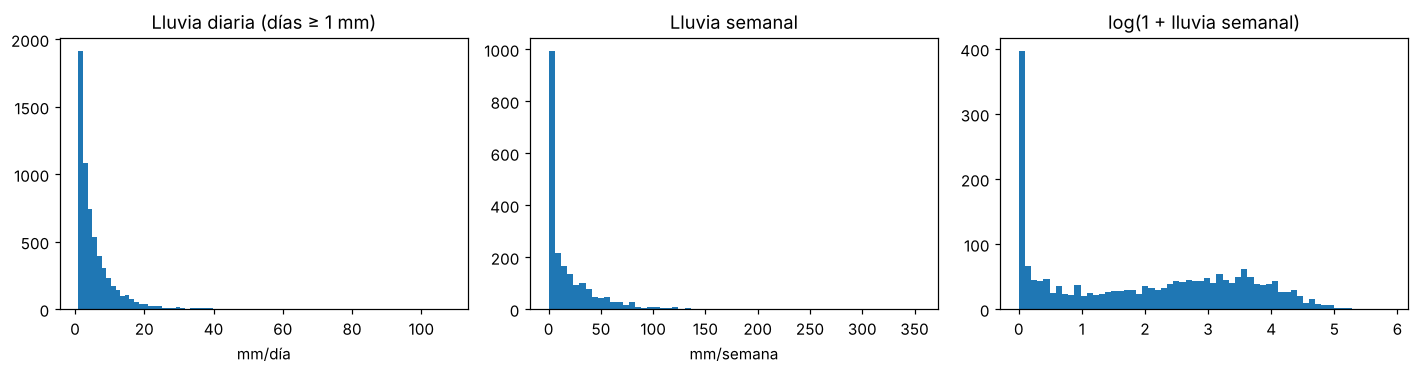

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].hist(P[P >= 1], bins=80); ax[0].set_title("Lluvia diaria (días ≥ 1 mm)"); ax[0].set_xlabel("mm/día")
ax[1].hist(Pw, bins=60); ax[1].set_title("Lluvia semanal"); ax[1].set_xlabel("mm/semana")
ax[2].hist(np.log1p(Pw), bins=60); ax[2].set_title("log(1 + lluvia semanal)")
plt.tight_layout(); plt.show()

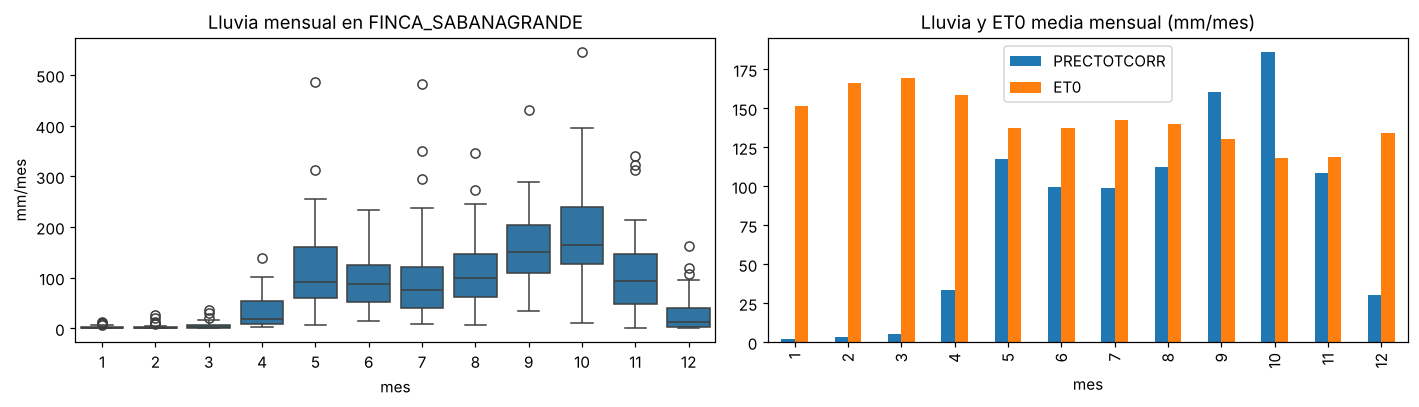

Lluvia y ET0 media mensual (mm/mes):
fecha           1      2      3      4      5      6      7      8      9      10     11     12
PRECTOTCORR    2.0    3.0    5.0   33.0  118.0   99.0   99.0  113.0  160.0  186.0  108.0   30.0
ET0          151.0  166.0  169.0  158.0  137.0  137.0  142.0  140.0  131.0  118.0  119.0  134.0


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
mens = train_df.assign(mes=train_df.fecha.dt.month, anio=train_df.fecha.dt.year)
mens = mens.groupby(["punto", "anio", "mes"])[OBJ].sum().reset_index()
sns.boxplot(data=mens[mens.punto == REF], x="mes", y=OBJ, ax=ax[0])
ax[0].set_title(f"Lluvia mensual en {REF}"); ax[0].set_ylabel("mm/mes")
clim_m = train_df.groupby(train_df.fecha.dt.month)[[OBJ, "ET0"]].mean() * 30.4
clim_m.plot.bar(ax=ax[1]); ax[1].set_title("Lluvia y ET0 media mensual (mm/mes)"); ax[1].set_xlabel("mes")
plt.tight_layout(); plt.show()
print("Lluvia y ET0 media mensual (mm/mes):"); print(clim_m.round(0).T.to_string())

**Interpretación.** La lluvia semanal tiene una media de 18,5 mm y una mediana de 7,0 mm, asimetría de 2,97 y curtosis de 17: pocas semanas muy lluviosas concentran buena parte del total. El 9,9 % de las semanas no tiene lluvia y el 31,6 % tiene menos de 1 mm. La transformación log(1+y) reduce la asimetría a 0,07. El ciclo anual es bimodal: enero–marzo casi sin lluvia (2 a 5 mm/mes), un primer pico en mayo (118 mm), una leve disminución en junio–julio (veranillo, unos 99 mm) y el máximo en octubre (186 mm). **Implicaciones:** (1) MAPE es inestable con semanas de lluvia nula o casi nula, así que se prioriza WAPE y MAE; (2) la validación debe ser cronológica por la fuerte estacionalidad; (3) la climatología por semana del año es una línea base exigente; (4) la transformación del objetivo se trata como hiperparámetro en el modelo base.

## 2.2 Análisis unidimensional

In [10]:
desc = train_df[VARS].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc["asimetría"] = train_df[VARS].skew()
desc["curtosis"] = train_df[VARS].kurt()
q1, q3 = train_df[VARS].quantile(.25), train_df[VARS].quantile(.75)
iqr = q3 - q1
desc["outliers_IQR_%"] = (((train_df[VARS] < q1 - 1.5 * iqr) | (train_df[VARS] > q3 + 1.5 * iqr)).mean() * 100)
desc.round(3)

,count,mean,std,min,5%,25%,50%,75%,95%,max,asimetría,curtosis,outliers_IQR_%
PRECTOTCORR,14610.0,2.638,5.433,0.000,0.000,0.010,0.470,2.968,11.990,108.040,5.853,66.046,10.630
T2M,14610.0,27.667,0.809,24.520,26.290,27.110,27.700,28.230,28.950,30.310,-0.149,-0.220,0.246
T2M_MAX,14610.0,30.406,1.216,25.390,28.370,29.610,30.410,31.220,32.370,34.750,-0.098,0.032,0.842
T2M_MIN,14610.0,25.962,0.901,22.430,24.340,25.380,26.070,26.620,27.280,28.660,-0.457,-0.137,0.575
RH2M,14610.0,79.884,4.936,63.690,71.310,76.300,80.340,83.688,87.220,92.550,-0.266,-0.571,0.089
WS2M,14610.0,4.154,1.349,0.750,1.830,3.170,4.220,5.170,6.260,8.150,-0.116,-0.684,0.000
ALLSKY_SFC_SW_DWN,13515.0,19.370,3.428,2.560,13.010,17.445,19.830,21.800,24.110,26.770,-0.824,0.957,1.930
PS,14610.0,100.543,0.128,100.080,100.330,100.460,100.540,100.630,100.760,101.050,0.057,0.153,0.931
GWETROOT,14610.0,0.712,0.119,0.580,0.590,0.600,0.680,0.800,0.940,1.000,0.689,-0.717,0.000
GWETTOP,14610.0,0.629,0.219,0.190,0.240,0.470,0.660,0.800,0.930,0.990,-0.457,-0.920,0.000


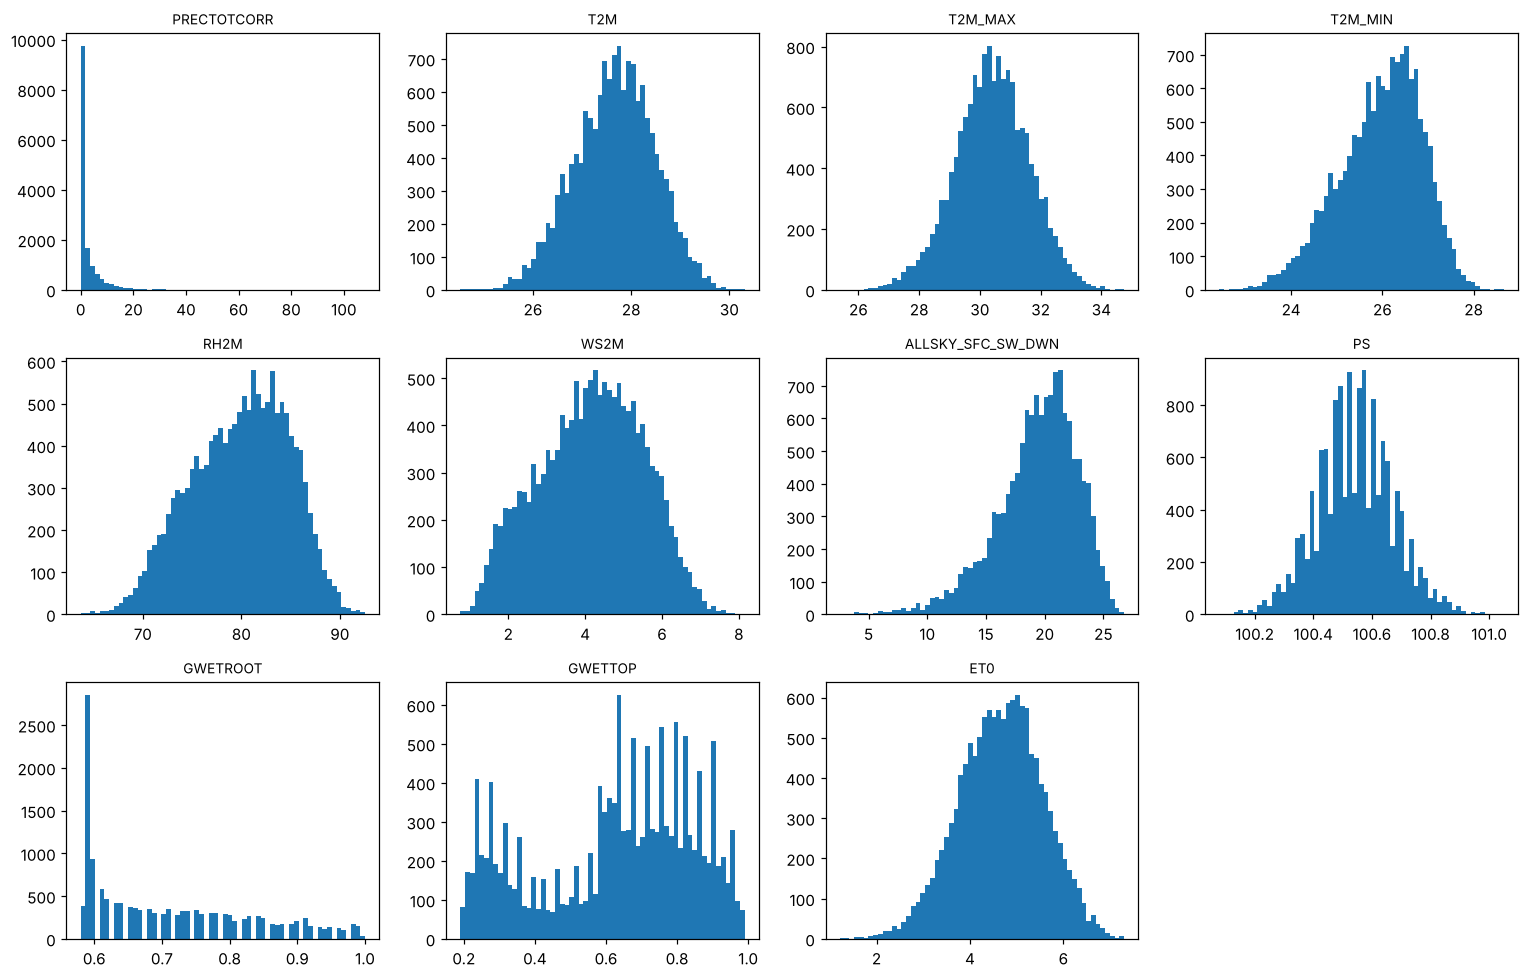

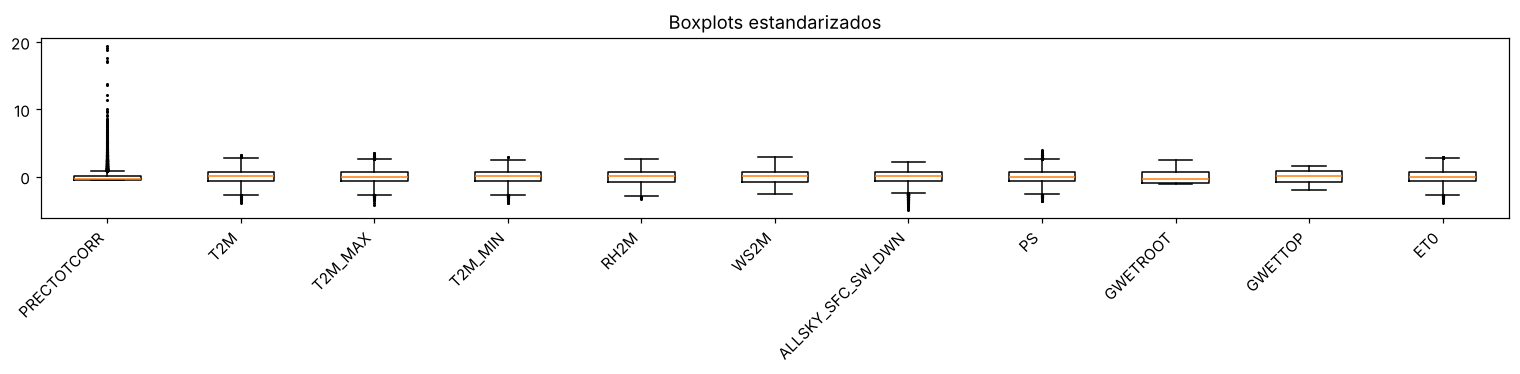

In [11]:
n = len(VARS); cols = 4; filas = int(np.ceil(n / cols))
fig, axs = plt.subplots(filas, cols, figsize=(14, 3 * filas))
for a, v in zip(axs.ravel(), VARS):
    a.hist(train_df[v].dropna(), bins=60); a.set_title(v, fontsize=9)
for a in axs.ravel()[n:]:
    a.axis("off")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 3.5))
z = (train_df[VARS] - train_df[VARS].mean()) / train_df[VARS].std()
ax.boxplot([z[v].dropna() for v in VARS], tick_labels=VARS, showfliers=True, flierprops={"markersize": 1})
ax.set_title("Boxplots estandarizados"); plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

**Normalidad.** Con decenas de miles de datos las pruebas de normalidad rechazan casi siempre, por eso se aplican a una muestra de 500 semanas y se interpretan junto con la asimetría y la curtosis, no por sí solas.

In [13]:
muestra = semanal.sample(min(500, len(semanal)), random_state=cfg.SEED)
pd.DataFrame({v: stats.normaltest(muestra[v].dropna()) for v in VARS}, index=["estadístico", "p"]).T.round(4)

,estadístico,p
PRECTOTCORR,289.8164,0.0000
T2M,2.8283,0.2431
T2M_MAX,1.1034,0.5760
T2M_MIN,20.7763,0.0000
RH2M,52.8930,0.0000
WS2M,34.5045,0.0000
ALLSKY_SFC_SW_DWN,5.2243,0.0734
PS,1.3347,0.5131
GWETROOT,54.9051,0.0000
GWETTOP,123.8187,0.0000


### Variables categóricas derivadas

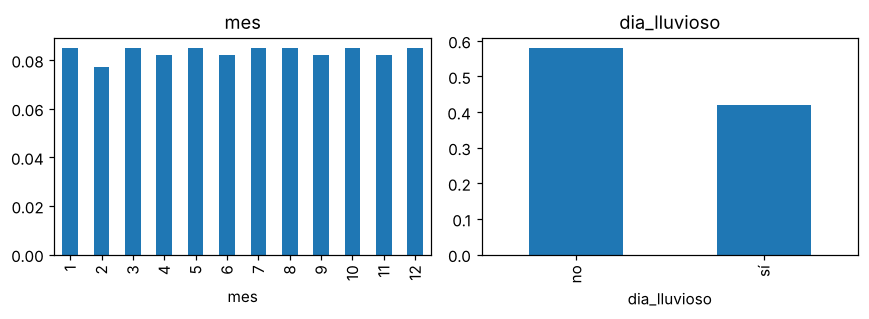

In [15]:
cat = pd.DataFrame({
    "mes": train_df.fecha.dt.month,
    "dia_lluvioso": np.where(train_df[OBJ] >= 1, "sí", "no"),
})
fig, axs = plt.subplots(1, cat.shape[1], figsize=(4 * cat.shape[1], 3))
for a, c in zip(np.atleast_1d(axs), cat.columns):
    cat[c].value_counts(normalize=True).sort_index().plot.bar(ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

In [16]:
prop = (train_df[OBJ] >= 1).groupby(train_df.fecha.dt.month).mean()
print("Proporción de días con lluvia >= 1 mm por mes:")
prop.round(2).rename("proporción").to_frame().T

Proporción de días con lluvia >= 1 mm por mes:


fecha,1,2,3,4,5,6,7,8,9,10,11,12
proporción,0.02,0.02,0.04,0.23,0.58,0.62,0.51,0.66,0.82,0.82,0.53,0.16


**Interpretación.** La precipitación es la única variable con asimetría (5,85) y curtosis (66) extremas; la regla IQR marca el 10,6 % de los días como atípicos, pero son lluvias reales y se conservan. Las temperaturas y la presión son casi simétricas: sobre una muestra de 500 semanas no se rechaza la normalidad de T2M, T2M_MAX ni PS; sí se rechaza para la lluvia, la humedad relativa y la humedad del suelo. La humedad del suelo superficial (GWETTOP) es bimodal, reflejo de los regímenes seco y húmedo. El viento medio de 4,2 m/s es alto por la cercanía a la costa y pesa en la ET0. La proporción de días con lluvia ≥ 1 mm va de 2 % en enero–febrero a 82 % en septiembre–octubre: la estacionalidad es el factor dominante.

## 2.3 Análisis bidimensional

Para que el análisis sirva al pronóstico, las predictoras se relacionan con la lluvia **de la semana siguiente** (horizonte h = 1), usando solo información pasada.

In [19]:
tab1 = md.tabla_modelado(train_df, h=1)
tab1 = tab1[tab1.fecha < cfg.INICIO_TEST]
pred_cols = md.columnas_predictoras(tab1)
print(len(tab1), "filas;", len(pred_cols), "predictoras")

2086 filas; 28 predictoras


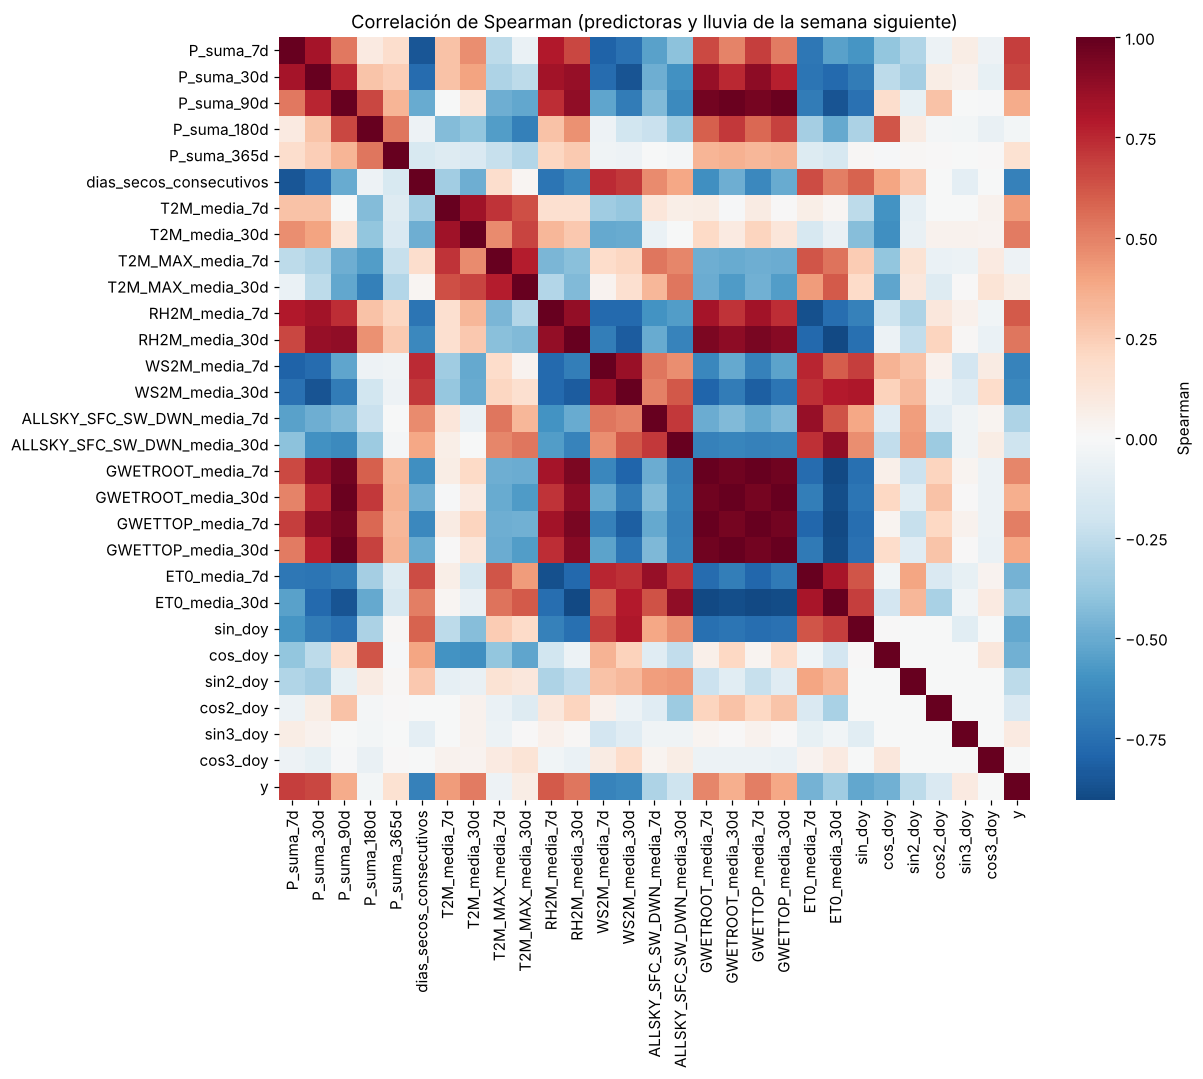

P_suma_7d                  0.693
dias_secos_consecutivos   -0.670
WS2M_media_7d             -0.664
P_suma_30d                 0.661
WS2M_media_30d            -0.638
RH2M_media_7d              0.607
RH2M_media_30d             0.535
T2M_media_30d              0.518
sin_doy                   -0.518
GWETTOP_media_7d           0.513
GWETROOT_media_7d          0.487
cos_doy                   -0.478
ET0_media_7d              -0.471
T2M_media_7d               0.424
GWETTOP_media_30d          0.386
Name: y, dtype: float64

In [20]:
corr = tab1[pred_cols + ["y"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "Spearman"})
ax.set_title("Correlación de Spearman (predictoras y lluvia de la semana siguiente)"); plt.show()
corr["y"].drop("y").sort_values(key=np.abs, ascending=False).round(3).head(15)

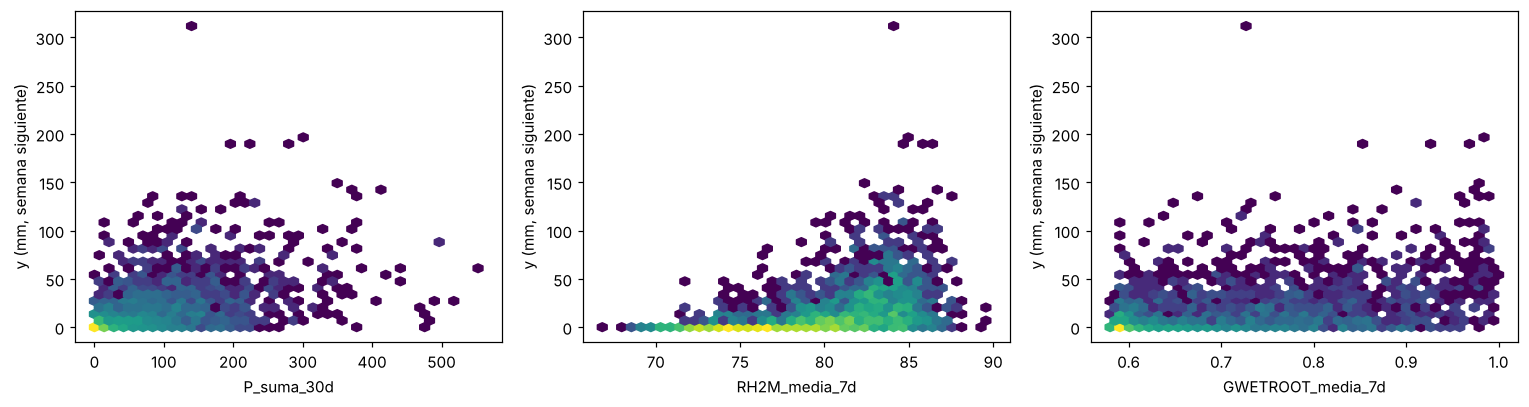

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for a, v in zip(axs, ["P_suma_30d", "RH2M_media_7d", "GWETROOT_media_7d"]):
    if v in tab1:
        a.hexbin(tab1[v], tab1["y"], gridsize=40, bins="log", mincnt=1); a.set_xlabel(v); a.set_ylabel("y (mm, semana siguiente)")
plt.tight_layout(); plt.show()

**Información mutua** (capta relaciones no lineales que la correlación no ve).

In [23]:
from sklearn.feature_selection import mutual_info_regression
X_mi = tab1[pred_cols].fillna(tab1[pred_cols].median())
mi = mutual_info_regression(X_mi, tab1["y"], random_state=cfg.SEED)
pd.Series(mi, index=pred_cols).sort_values(ascending=False).round(4).head(15)

dias_secos_consecutivos    0.3305
P_suma_7d                  0.3098
WS2M_media_7d              0.2945
sin_doy                    0.2922
P_suma_30d                 0.2845
WS2M_media_30d             0.2628
sin3_doy                   0.2336
cos_doy                    0.2276
RH2M_media_7d              0.2109
P_suma_365d                0.1972
cos2_doy                   0.1778
T2M_media_30d              0.1708
cos3_doy                   0.1680
RH2M_media_30d             0.1633
GWETTOP_media_7d           0.1509
dtype: float64

### Categóricas vs numérica: pruebas no paramétricas con tamaño de efecto

Se usa Kruskal-Wallis porque la lluvia no es normal. El tamaño de efecto es $\varepsilon^2 = H/(n-1)$. Como se hacen varias pruebas, los valores p se corrigen con Holm.

In [25]:
from src.series import holm
pruebas = []
t = tab1.assign(mes=tab1.fecha.dt.month, decada=(tab1.fecha.dt.year // 10) * 10)
for factor in ["mes", "decada"]:
    grupos = [g["y"].values for _, g in t.groupby(factor, observed=True)]
    if len(grupos) < 2:
        print(f"{factor}: un solo grupo, se omite"); continue
    H, p = stats.kruskal(*grupos)
    pruebas.append((factor, H, p, H / (len(t) - 1)))
res = pd.DataFrame(pruebas, columns=["factor", "H", "p", "epsilon2"])
res["p_Holm"] = holm(res["p"])
res.round(5)

,factor,H,p,epsilon2,p_Holm
0,mes,1206.93185,0.0,0.57886,0.0
1,decada,37.91633,0.0,0.01819,0.0


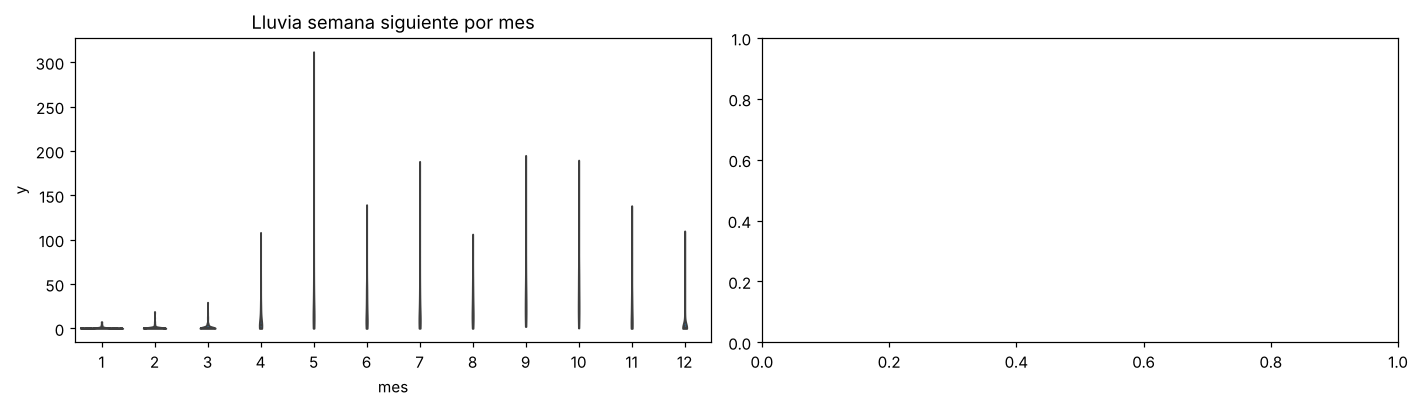

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
sns.violinplot(data=t, x="mes", y="y", ax=axs[0], cut=0, inner="quartile"); axs[0].set_title("Lluvia semana siguiente por mes")
if "fase_enso" in t:
    sns.boxplot(data=t, x="fase_enso", y="y", ax=axs[1], showfliers=False); axs[1].set_title("Por fase ENSO")
plt.tight_layout(); plt.show()

### Categóricas vs categóricas: $\chi^2$ y V de Cramér

In [28]:
def cramer_v(tabla):
    chi2, p, gl, _ = stats.chi2_contingency(tabla)
    n = tabla.values.sum()
    return chi2, p, np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

t["semana_lluviosa"] = np.where(t["y"] >= 10, "≥10 mm", "<10 mm")
for factor in [c for c in ["mes", "fase_enso"] if c in t]:
    ct = pd.crosstab(t[factor], t["semana_lluviosa"])
    if min(ct.shape) < 2:
        print(f"{factor}: una sola categoría, se omite"); continue
    chi2, p, v = cramer_v(ct)
    print(f"{factor}: chi2 = {chi2:.1f}, p = {p:.2e}, V de Cramér = {v:.3f}")
pd.crosstab(t["mes"], t["semana_lluviosa"], normalize="index").round(2)

mes: chi2 = 859.1, p = 3.87e-177, V de Cramér = 0.642


semana_lluviosa,<10 mm,≥10 mm
mes,,
1,1.00,0.00
2,0.98,0.02
3,0.97,0.03
4,0.70,0.30
5,0.32,0.68
6,0.40,0.60
7,0.46,0.54
8,0.25,0.75
9,0.13,0.87


### Multicolinealidad (VIF)

In [30]:
from src.series import vif as calcular_vif
Xv = tab1[pred_cols].dropna()
Xv = Xv.sample(min(20000, len(Xv)), random_state=cfg.SEED)
Xv = Xv.loc[:, Xv.std() > 0]
Xv = (Xv - Xv.mean()) / Xv.std()
vif = calcular_vif(Xv)
vif.sort_values(ascending=False).round(1)

ET0_media_30d                  786.5
ET0_media_7d                   374.0
RH2M_media_30d                 224.0
ALLSKY_SFC_SW_DWN_media_30d    113.8
RH2M_media_7d                   91.8
GWETROOT_media_30d              85.7
GWETROOT_media_7d               82.0
ALLSKY_SFC_SW_DWN_media_7d      73.0
GWETTOP_media_30d               64.8
WS2M_media_30d                  63.5
GWETTOP_media_7d                51.0
T2M_media_30d                   47.2
T2M_MAX_media_30d               34.0
T2M_media_7d                    29.4
WS2M_media_7d                   25.7
P_suma_90d                      23.9
T2M_MAX_media_7d                20.4
P_suma_180d                     13.2
sin_doy                         11.5
cos_doy                         11.5
P_suma_30d                      10.8
cos2_doy                         5.3
P_suma_365d                      3.7
P_suma_7d                        2.9
sin2_doy                         2.9
dias_secos_consecutivos          2.5
cos3_doy                         1.6
s

**Interpretación.** Las asociaciones más fuertes con la lluvia de la semana siguiente son la lluvia de los últimos 7 días (ρ = 0,69), los días secos consecutivos (ρ = −0,67) y el viento de los últimos 7 días (ρ = −0,66). El signo negativo del viento es físicamente coherente: los alisios intensos de la temporada seca, asociados al chorro de bajo nivel del Caribe, coinciden con ausencia de lluvia. La información mutua confirma el orden y destaca los términos del calendario, que capturan relaciones no lineales. El mes explica una gran parte de la variación (Kruskal-Wallis, ε² ≈ 0,58, efecto grande; V de Cramér ≈ 0,64 entre mes y semana lluviosa); la década, aunque significativa por el tamaño de muestra, tiene un efecto pequeño (ε² ≈ 0,02): con muestras grandes el tamaño de efecto, y no el valor p, indica relevancia. **Multicolinealidad:** el déficit de 30 días era combinación lineal exacta de la ET0 y la lluvia de 30 días (colinealidad perfecta, VIF prácticamente infinito) y se eliminó del conjunto de predictoras. Las medias de ET0, humedad y radiación siguen con VIF altos porque la ET0 se calcula con ellas; se conservan con regularización L2 del SVR y sus coeficientes no se interpretan por separado.

## 2.4 Análisis multivariado

Componentes para 80 % y 95 % de varianza: 6 12
Varianza explicada: PC1 = 46.3%, PC2 = 16.1%


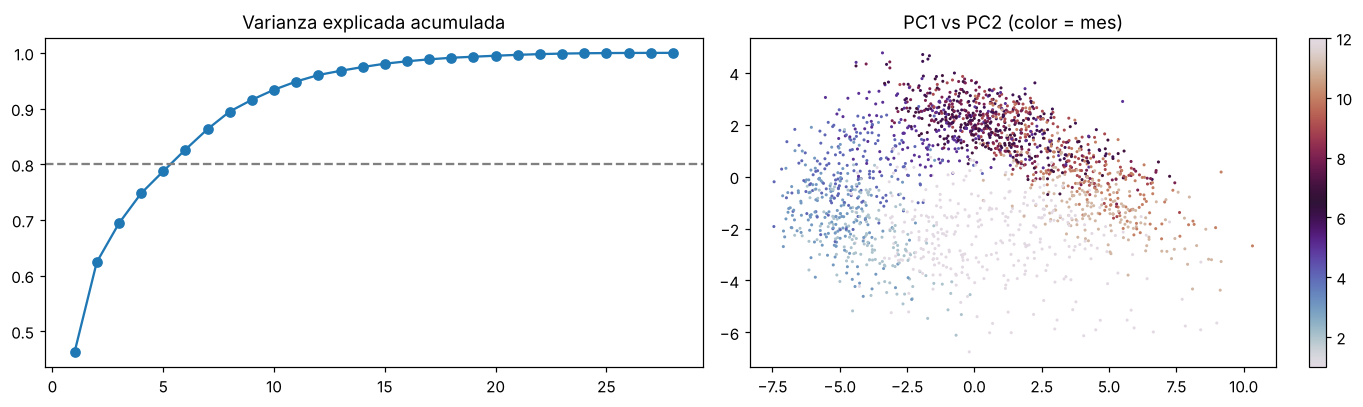

,PC1,PC2,PC3
P_suma_7d,0.17,0.08,0.02
P_suma_30d,0.23,0.06,0.14
P_suma_90d,0.24,-0.09,0.25
P_suma_180d,0.16,-0.28,0.30
P_suma_365d,0.08,-0.12,0.40
dias_secos_consecutivos,-0.17,-0.18,0.07
T2M_media_7d,0.01,0.42,0.15
T2M_media_30d,0.06,0.43,0.07
T2M_MAX_media_7d,-0.15,0.30,0.20
T2M_MAX_media_30d,-0.14,0.36,0.07


In [33]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
Xm = tab1[pred_cols].dropna()
Xs = StandardScaler().fit_transform(Xm)
pca = PCA(random_state=cfg.SEED).fit(Xs)
acum = np.cumsum(pca.explained_variance_ratio_)
print("Componentes para 80 % y 95 % de varianza:", np.argmax(acum >= .8) + 1, np.argmax(acum >= .95) + 1)
print(f"Varianza explicada: PC1 = {pca.explained_variance_ratio_[0]:.1%}, PC2 = {pca.explained_variance_ratio_[1]:.1%}")
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].plot(range(1, len(acum) + 1), acum, marker="o"); axs[0].axhline(.8, ls="--", c="grey"); axs[0].set_title("Varianza explicada acumulada")
Z = pca.transform(Xs)[:, :2]
sc = axs[1].scatter(Z[:, 0], Z[:, 1], c=tab1.loc[Xm.index, "fecha"].dt.month, s=1, cmap="twilight")
axs[1].set_title("PC1 vs PC2 (color = mes)"); plt.colorbar(sc, ax=axs[1])
plt.tight_layout(); plt.show()
pd.DataFrame(pca.components_[:3].T, index=Xm.columns, columns=["PC1", "PC2", "PC3"]).round(2)

### Outliers multivariados

In [35]:
from sklearn.ensemble import IsolationForest
from sklearn.covariance import MinCovDet
iso = IsolationForest(contamination="auto", random_state=cfg.SEED).fit(Xs)
atipico_iso = iso.predict(Xs) == -1
mcd = MinCovDet(random_state=cfg.SEED).fit(Xs[np.random.default_rng(cfg.SEED).choice(len(Xs), min(5000, len(Xs)), replace=False)])
d2 = mcd.mahalanobis(Xs)
atipico_mah = d2 > stats.chi2.ppf(0.999, Xs.shape[1])
print(f"Isolation Forest: {atipico_iso.mean():.2%}  |  Mahalanobis robusta (p<0.001): {atipico_mah.mean():.2%}  |  ambos: {(atipico_iso & atipico_mah).mean():.2%}")
print(tab1.loc[Xm.index[atipico_iso & atipico_mah], "fecha"].dt.year.value_counts().head(10))

Isolation Forest: 15.73%  |  Mahalanobis robusta (p<0.001): 52.28%  |  ambos: 10.90%
fecha
2017    31
2011    24
2010    16
2020    14
1985    13
2012    13
2018    13
1992     9
2000     8
2003     7
Name: count, dtype: int64


### Estructura de grupos (regímenes climáticos)

In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
idx = np.random.default_rng(cfg.SEED).choice(len(Xs), min(8000, len(Xs)), replace=False)
Z5 = pca.transform(Xs)[:, :5]
for k in range(2, 7):
    km = KMeans(k, n_init=10, random_state=cfg.SEED).fit(Z5[idx])
    print(k, round(silhouette_score(Z5[idx], km.labels_), 3))

2 0.345
3 0.333
4 0.344
5 0.322
6 0.276


In [38]:
k = 2  # ajustar según la silueta
km = KMeans(k, n_init=10, random_state=cfg.SEED).fit(Z5)
g = tab1.loc[Xm.index].assign(grupo=km.labels_)
g.groupby("grupo").agg(y_media=("y", "mean"), n=("y", "size")).join(
    g.groupby("grupo")["fecha"].apply(lambda s: s.dt.month.mode().iloc[0]).rename("mes_modal"))

,y_media,n,mes_modal
grupo,,,
0,28.270421,1044,10
1,7.724977,882,3


**Interpretación.** El primer componente explica alrededor del 46 % de la varianza y agrupa humedad del suelo y humedad relativa con signo opuesto a la ET0: es un eje de régimen húmedo frente a seco. El segundo (16 %) combina temperatura y ciclo anual. Se necesitan 6 componentes para el 80 % de la varianza y 12 para el 95 %: la dimensionalidad efectiva es mucho menor que el número de predictoras, coherente con el VIF. La distancia de Mahalanobis robusta marca como atípica una fracción muy alta de semanas, señal de que la distribución conjunta está lejos de la normal; Isolation Forest es más adecuado. Las semanas atípicas se concentran en 2017, 2011 y 2010, años de La Niña con lluvias extremas: son eventos reales y se conservan. El agrupamiento con dos grupos separa un régimen húmedo (mes típico octubre) de uno seco (mes típico marzo).

## 2.5 Auditoría de fuga de datos

Cada predictora debe estar disponible en el momento de emitir el pronóstico. En este proyecto eso significa: todas las variables de POWER se usan rezagadas `cfg.LATENCIA_DIAS` días y resumidas con ventanas del pasado; los componentes cíclicos del calendario sí se conocen de antemano.

In [41]:
disponibilidad = pd.DataFrame({
    "predictora": pred_cols,
    "disponible en t": ["sí (calendario)" if c.startswith(("sin", "cos")) else
                        "sí (estática)" if c in ("lat", "lon", "elevacion_m") else
                        f"sí (pasado, rezago {cfg.LATENCIA_DIAS} d)" for c in pred_cols],
})
disponibilidad

,predictora,disponible en t
0,P_suma_7d,"sí (pasado, rezago 3 d)"
1,P_suma_30d,"sí (pasado, rezago 3 d)"
2,P_suma_90d,"sí (pasado, rezago 3 d)"
3,P_suma_180d,"sí (pasado, rezago 3 d)"
4,P_suma_365d,"sí (pasado, rezago 3 d)"
5,dias_secos_consecutivos,"sí (pasado, rezago 3 d)"
6,T2M_media_7d,"sí (pasado, rezago 3 d)"
7,T2M_media_30d,"sí (pasado, rezago 3 d)"
8,T2M_MAX_media_7d,"sí (pasado, rezago 3 d)"
9,T2M_MAX_media_30d,"sí (pasado, rezago 3 d)"


**Desempeño univariado.** Cada predictora sola en un árbol poco profundo con validación cronológica. Un R² cercano a 1 sería señal de fuga.

In [43]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score
r2_uni = {}
splits = list(md.cv_temporal(tab1.fecha, n_splits=3, gap_dias=7 + cfg.LATENCIA_DIAS))
for c in pred_cols:
    vals = []
    for tr, va in splits:
        a, b = tab1.iloc[tr], tab1.iloc[va]
        ok_a, ok_b = a[c].notna(), b[c].notna()
        m = DecisionTreeRegressor(max_depth=3, random_state=cfg.SEED).fit(a.loc[ok_a, [c]], a.loc[ok_a, "y"])
        vals.append(r2_score(b.loc[ok_b, "y"], m.predict(b.loc[ok_b, [c]])))
    r2_uni[c] = np.mean(vals)
pd.Series(r2_uni).sort_values(ascending=False).round(3)

dias_secos_consecutivos        0.202
P_suma_7d                      0.197
P_suma_30d                     0.177
WS2M_media_30d                 0.173
WS2M_media_7d                  0.167
RH2M_media_7d                  0.165
GWETTOP_media_7d               0.135
sin_doy                        0.132
RH2M_media_30d                 0.121
GWETROOT_media_7d              0.100
P_suma_90d                     0.099
T2M_media_30d                  0.077
GWETROOT_media_30d             0.063
ET0_media_7d                   0.050
ET0_media_30d                  0.049
cos_doy                        0.045
GWETTOP_media_30d              0.032
T2M_media_7d                   0.021
ALLSKY_SFC_SW_DWN_media_30d   -0.003
sin3_doy                      -0.012
cos2_doy                      -0.015
sin2_doy                      -0.016
ALLSKY_SFC_SW_DWN_media_7d    -0.020
cos3_doy                      -0.025
T2M_MAX_media_30d             -0.041
T2M_MAX_media_7d              -0.048
P_suma_365d                   -0.051
P

**Contraejemplo didáctico:** la humedad relativa del *mismo* periodo del objetivo explica mucho más, pero no se conoce al momento de pronosticar. Por eso no se usa.

In [45]:
g = train_df[train_df.punto == REF].set_index("fecha").sort_index()
y1 = md.objetivo_semana_h(g[OBJ], 1)
rh_futura = g["RH2M"][::-1].rolling(7).mean()[::-1].shift(-1)   # HR de la misma semana objetivo: FUGA
rh_pasada = g["RH2M"].rolling(7).mean().shift(cfg.LATENCIA_DIAS)
print("Spearman con HR de la semana objetivo (fuga):", round(y1.corr(rh_futura, method="spearman"), 3))
print("Spearman con HR pasada (válida):             ", round(y1.corr(rh_pasada, method="spearman"), 3))

Spearman con HR de la semana objetivo (fuga): 0.798
Spearman con HR pasada (válida):              0.603


In [46]:
te_ = df[df.fecha >= cfg.INICIO_TEST]
print("Fechas compartidas entre entrenamiento y prueba:", len(set(train_df.fecha) & set(te_.fecha)))
print("La separación entre entrenamiento y prueba es cronológica (1981–2020 frente a 2021–2025).")


Fechas compartidas entre entrenamiento y prueba: 0
La separación entre entrenamiento y prueba es cronológica (1981–2020 frente a 2021–2025).


**Interpretación.** Ninguna predictora sola se acerca a un ajuste perfecto (R² univariado máximo ≈ 0,20, días secos consecutivos), así que no hay variables derivadas del objetivo. Todas las variables de POWER se usan con 3 días de rezago (latencia de publicación) y los términos del calendario se conocen de antemano. Como contraejemplo, la humedad relativa de la misma semana que se pronostica tiene una correlación de 0,80 con la lluvia, frente a 0,60 de la humedad pasada: usarla inflaría el desempeño con información no disponible al pronosticar. Se descarta toda variable del mismo periodo del objetivo; no hay fechas compartidas entre entrenamiento y prueba y se purgan las filas cuya semana objetivo cae en 2021.

## 2.6 Componente temporal

In [49]:
for p_, g in train_df.groupby("punto"):
    d = g.fecha.sort_values().diff().dt.days
    print(f"{p_}: frecuencia modal = {d.mode().iloc[0]} día(s), saltos > 1 día = {(d > 1).sum()}, marcas duplicadas = {g.fecha.duplicated().sum()}")
print("Zona horaria: los días corresponden a la hora estándar local (LST) solicitada a la API; no hay horas que ajustar.")

FINCA_SABANAGRANDE: frecuencia modal = 1.0 día(s), saltos > 1 día = 0, marcas duplicadas = 0
Zona horaria: los días corresponden a la hora estándar local (LST) solicitada a la API; no hay horas que ajustar.


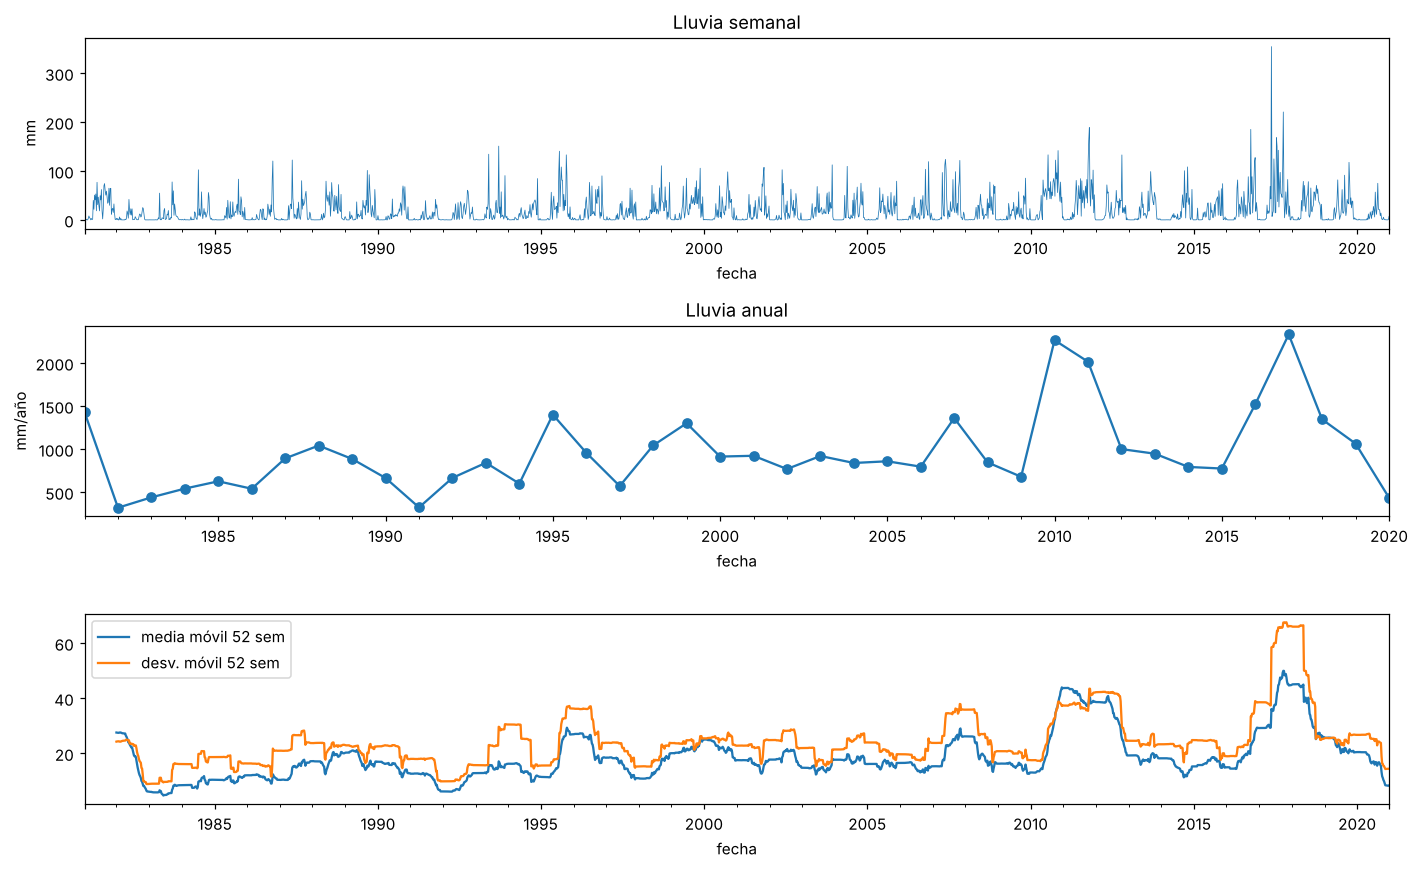

In [50]:
fig, axs = plt.subplots(3, 1, figsize=(13, 8))
obj_sem[OBJ].plot(ax=axs[0], lw=.5); axs[0].set_title("Lluvia semanal"); axs[0].set_ylabel("mm")
obj_sem[OBJ].resample("YE").sum().plot(ax=axs[1], marker="o"); axs[1].set_title("Lluvia anual"); axs[1].set_ylabel("mm/año")
obj_sem[OBJ].rolling(52).mean().plot(ax=axs[2], label="media móvil 52 sem")
obj_sem[OBJ].rolling(52).std().plot(ax=axs[2], label="desv. móvil 52 sem"); axs[2].legend()
plt.tight_layout(); plt.show()

### Descomposición en tendencia, estacionalidad y residuo (periodo 52 semanas)

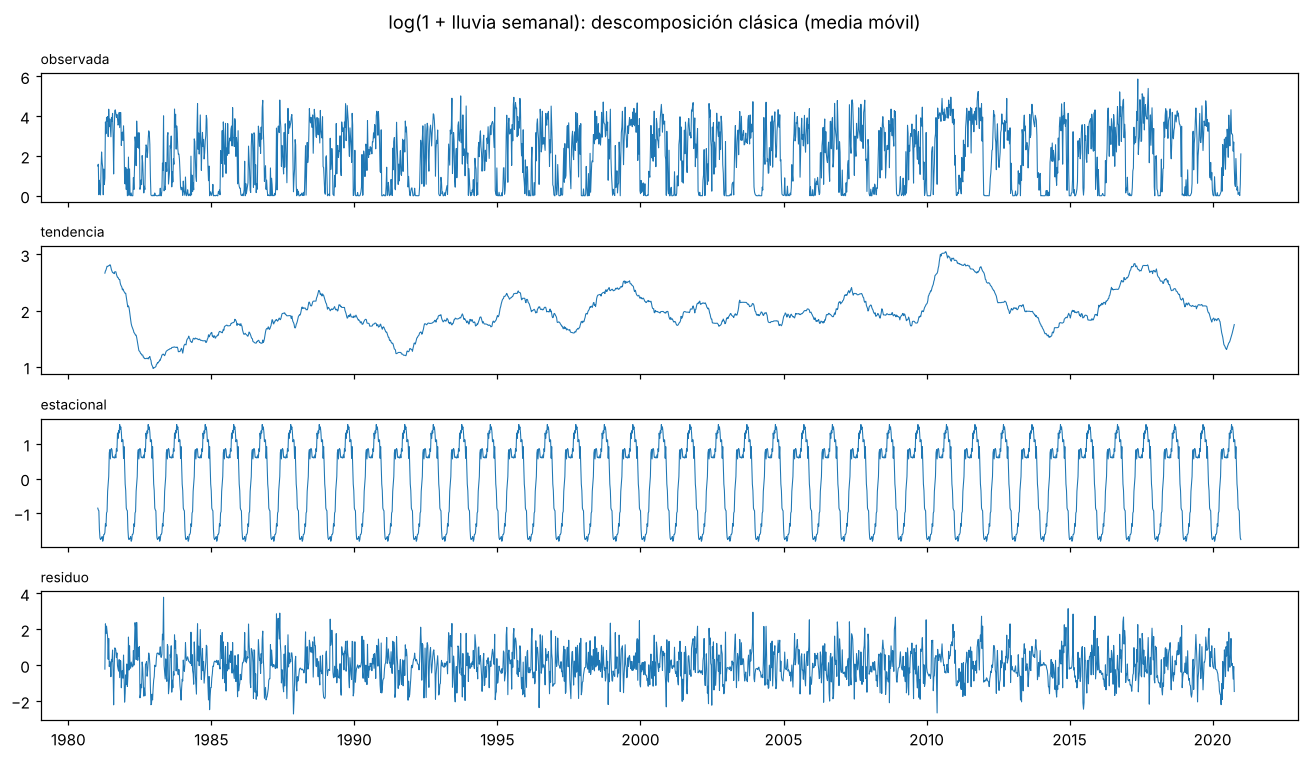

Fuerza de la estacionalidad: 0.60   Fuerza de la tendencia: 0.17


In [52]:
from src import series
serie = obj_sem[OBJ].asfreq("W-SUN").fillna(0)
desc, metodo = series.descomponer(np.log1p(serie), periodo=52)
fig, axs = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for a, c in zip(axs, desc.columns):
    a.plot(desc.index, desc[c], lw=.7); a.set_title(c, loc="left", fontsize=9)
plt.suptitle(f"log(1 + lluvia semanal): descomposición {metodo}"); plt.tight_layout(); plt.show()
fe, ft = series.fuerza(desc)
print(f"Fuerza de la estacionalidad: {fe:.2f}   Fuerza de la tendencia: {ft:.2f}")

### Estacionariedad: ADF y KPSS

ADF tiene como hipótesis nula una raíz unitaria; KPSS tiene como nula la estacionariedad. Se interpretan juntas.

In [54]:
filas = []
for nombre, s in {"log(1 + lluvia semanal)": np.log1p(serie), "ET0 semanal": obj_sem["ET0"].asfreq("W-SUN").interpolate().dropna()}.items():
    ea, pa = series.adf(s); ek, pk = series.kpss(s)
    filas.append({"serie": nombre, "ADF": ea, "p ADF": pa, "KPSS": ek, "p KPSS": pk})
pd.DataFrame(filas).round(4)

,serie,ADF,p ADF,KPSS,p KPSS
0,log(1 + lluvia semanal),-12.2426,0.01,0.4048,0.10
1,ET0 semanal,-5.5103,0.01,1.7044,0.01


### Dependencia temporal: ACF, PACF y correlación cruzada

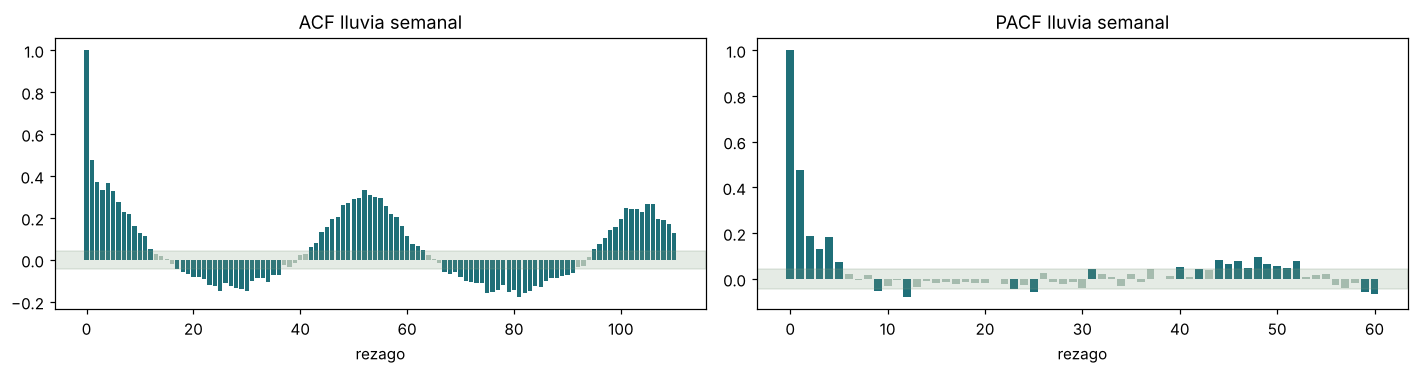

In [56]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.5))
series.graficar_acf(axs[0], series.acf(serie.values, 110), len(serie), "ACF lluvia semanal")
series.graficar_acf(axs[1], series.pacf(serie.values, 60), len(serie), "PACF lluvia semanal")
plt.tight_layout(); plt.show()

In [57]:
# Resumen cuantitativo del componente temporal (respalda la interpretación)
a_ = series.acf(serie.values, 110); banda = 1.96 / np.sqrt(len(serie))
consec = int(np.argmax(np.abs(a_[1:]) < banda)) if (np.abs(a_[1:]) < banda).any() else 110
anual_ = obj_sem[OBJ].resample("YE").sum(); anual_ = anual_[anual_.index.year < pd.Timestamp(cfg.INICIO_TEST).year]
anual_.index = anual_.index.year
t_anual = train_df.set_index("fecha")["T2M"].resample("YE").mean(); t_anual.index = t_anual.index.year
tp, tt = stats.linregress(anual_.index, anual_.values), stats.linregress(t_anual.index, t_anual.values)
pd.Series({
    "ACF rezago 1": round(a_[1], 3), "ACF rezago 52": round(a_[52], 3),
    "semanas seguidas con ACF significativa": consec,
    "coef. de variación de la lluvia anual": round(anual_.std() / anual_.mean(), 3),
    "año más seco (mm)": f"{anual_.idxmin()} ({anual_.min():.0f})", "año más lluvioso (mm)": f"{anual_.idxmax()} ({anual_.max():.0f})",
    "tendencia lluvia (mm/década, p)": f"{tp.slope * 10:.0f} (p = {tp.pvalue:.3f})",
    "tendencia temperatura (°C/década, p)": f"{tt.slope * 10:.2f} (p = {tt.pvalue:.3f})",
}).to_frame("valor")

,valor
ACF rezago 1,0.478
ACF rezago 52,0.331
semanas seguidas con ACF significativa,12
coef. de variación de la lluvia anual,0.483
año más seco (mm),1982 (320)
año más lluvioso (mm),2017 (2333)
"tendencia lluvia (mm/década, p)",168 (p = 0.007)
"tendencia temperatura (°C/década, p)",0.11 (p = 0.002)


### Cambios de régimen: prueba de Pettitt sobre la lluvia anual

In [59]:
def pettitt(x):
    x = np.asarray(x); n = len(x)
    r = stats.rankdata(x)
    U = np.array([2 * r[:k].sum() - k * (n + 1) for k in range(1, n)])
    K = np.abs(U).max(); k = np.abs(U).argmax()
    return k + 1, K, min(1, 2 * np.exp(-6 * K**2 / (n**3 + n**2)))

anual = obj_sem[OBJ].resample("YE").sum()
anual = anual[anual.index.year < pd.Timestamp(cfg.INICIO_TEST).year]
k, K, p = pettitt(anual.values)
print(f"Punto de cambio más probable: {anual.index[k].year}  (K = {K:.0f}, p = {p:.3f})")

Punto de cambio más probable: 1995  (K = 210, p = 0.035)


### Deriva: comparación de distribuciones por década

In [61]:
dec = semanal[semanal.punto == REF].assign(decada=lambda d: (d.fecha.dt.year // 10) * 10)
base = dec[dec.decada == dec.decada.min()]
filas = []
for v in [OBJ, "ET0", "T2M", "RH2M", "GWETROOT"]:
    for d_, g in dec.groupby("decada"):
        if d_ == dec.decada.min():
            continue
        ks = stats.ks_2samp(base[v].dropna(), g[v].dropna())
        filas.append((v, d_, g[v].mean() - base[v].mean(), stats.wasserstein_distance(base[v].dropna(), g[v].dropna()), ks.pvalue))
deriva = pd.DataFrame(filas, columns=["variable", "década", "Δ media vs 1ª década", "Wasserstein", "p KS"])
deriva["p_Holm"] = holm(deriva["p KS"])
deriva.round(3)

,variable,década,Δ media vs 1ª década,Wasserstein,p KS,p_Holm
0,PRECTOTCORR,1990,1.739,1.836,0.216,0.865
1,PRECTOTCORR,2000,2.737,2.739,0.120,0.688
2,PRECTOTCORR,2010,12.609,12.611,0.000,0.000
3,PRECTOTCORR,2020,-5.952,5.952,0.115,0.688
4,ET0,1990,11.136,11.136,0.000,0.000
5,ET0,2000,11.318,11.318,0.000,0.000
6,ET0,2010,10.551,10.559,0.000,0.000
7,ET0,2020,12.999,13.003,0.000,0.000
8,T2M,1990,0.074,0.076,0.344,0.865
9,T2M,2000,0.242,0.242,0.000,0.000


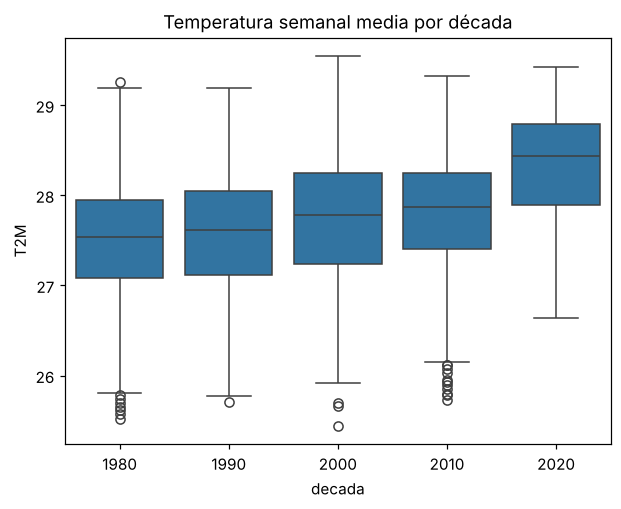

In [62]:
sns.boxplot(data=dec, x="decada", y="T2M"); plt.title("Temperatura semanal media por década"); plt.show()

**Interpretación.** La estacionalidad domina la serie (fuerza estacional ≈ 0,60 frente a ≈ 0,17 de la tendencia). La lluvia es estacionaria alrededor de su ciclo: KPSS no rechaza la estacionariedad al 5 % y ADF rechaza con amplitud la raíz unitaria. La ET0, en cambio, muestra un cambio de nivel (KPSS rechaza la estacionariedad): sube unos 11 mm/semana desde los años noventa respecto a 1984–1989 (la década de 2020 en entrenamiento solo contiene el año 2020), lo que puede deberse a un cambio en el producto de radiación más que al clima. La ACF muestra memoria de corto plazo (ρ₁ ≈ 0,48, significativa durante unas 12 semanas seguidas) y el ciclo anual (ρ₅₂ ≈ 0,33); la PACF cae después de los primeros rezagos. La lluvia anual varía mucho entre años (coeficiente de variación ≈ 0,48): el año más seco fue 1982 (unos 320 mm) y los más lluviosos, 2010–2011 y 2017, que coinciden con años de El Niño y La Niña reportados por NOAA (el ONI no forma parte de este dataset). Hay una tendencia positiva de la lluvia (168 mm por década, p = 0,007, impulsada por 2010–2018) y la prueba de Pettitt ubica un cambio en 1995 (p ≈ 0,035); la temperatura sube unos 0,11 °C por década. **Consecuencias:** partición cronológica con purga; validación de ventana creciente con separación de 7h + 3 días; predictoras de hasta 365 días; armónicos del ciclo anual; y vigilancia de la deriva, que puede degradar el modelo en el periodo de prueba.

## 2.7 Preprocesamiento: decisiones trazables al EDA

Todo se implementa dentro de un `Pipeline` ajustado solo con entrenamiento (ver `src/modelado.py`).

| Decisión | Hallazgo del EDA que la motiva |
|---|---|
| Imputación por mediana dentro del Pipeline | Faltantes de radiación en 1981–1983, mecanismo MAR respecto a la fecha (notebook 01) |
| Escalado estándar | Magnitudes muy distintas entre variables (2.2) |
| Conservar outliers | Extremos reales asociados a La Niña (2.2, 2.4) |
| Sumas y medias móviles pasadas de 7 a 365 días, con 3 días de rezago | Memoria de la ACF y ciclo anual (2.6); latencia de publicación (2.5) |
| Tres armónicos del día del año | Ciclo bimodal que un solo seno y coseno no representa (2.1, 2.6) |
| Eliminar el déficit de 30 días | Combinación lineal exacta de ET0 y lluvia: colinealidad perfecta (2.3) |
| Regularización L2 del SVR | Colinealidad de ET0, humedad y radiación (2.3, 2.4) |
| Transformación del objetivo como hiperparámetro | Asimetría de la lluvia (2.1) |
| Partición cronológica con purga y separación de 7h + 3 días | Dependencia temporal y estacionalidad (2.6) |